<a href="https://colab.research.google.com/github/faiz-al123/ProyekAkhir_5A_Students_Performancein_Exams/blob/main/03_varian_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyek Akhir Pembelajaran Mesin (INF62325)
## 03 — Varian 1 (Dasar): k-NN dengan k = 5

| | |
|---|---|
| **Nama** | Ahmad Aly |
| **NIM** | 2488010069 |
| **Kelompok / Kelas** | Informatika A — paket *StudentsPerformance* |
| **Metode** | Klasifikasi (k-NN dibandingkan Naive Bayes) |
| **Varian** | Anggota 1 — Dasar (tolok ukur) |

**Pertanyaan analitik:** Bagaimana kinerja k-NN dalam mengklasifikasikan status kursus persiapan ujian siswa (`completed` / `none`) berdasarkan gender, ras/etnis, pendidikan orang tua, jenis makan siang, serta nilai matematika, membaca, dan menulis?


## Sel 1 — Import Library

In [1]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings('ignore')

# Konfigurasi bersama. SAMAKAN dengan Anggota 2 dan 3 agar perbandingan adil.
RANDOM_STATE = 42
TEST_SIZE = 0.2
K = 5

print("Library berhasil diimport!")

Library berhasil diimport!


## Sel 2 — Memuat Dataset
Unggah berkas `StudentsPerformance.xls` (atau `StudentsPerformance_Cleaned.csv` hasil notebook praproses). Sel ini juga bisa membaca berkas yang sudah ada di folder kerja.

In [2]:
def baca_data(sumber):
    # Berkas bisa berformat CSV atau Excel meskipun berekstensi .xls
    try:
        return pd.read_csv(sumber)
    except Exception:
        if hasattr(sumber, 'seek'):
            sumber.seek(0)
        return pd.read_excel(sumber)

try:
    from google.colab import files
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]
    df = baca_data(io.BytesIO(uploaded[file_name]))
except ImportError:
    # Di luar Colab: ganti dengan path berkas Anda
    file_name = 'StudentsPerformance.xls'
    df = baca_data(file_name)

# Buang kolom turunan 'average_score' jika memakai berkas hasil praproses
df = df.drop(columns=['average_score'], errors='ignore')
df.columns = df.columns.str.strip()

print(f"Dataset '{file_name}' berhasil dimuat!")
print("Ukuran dataset (baris, kolom):", df.shape)
display(df.head())

Saving StudentsPerformance.xls to StudentsPerformance.xls
Dataset 'StudentsPerformance.xls' berhasil dimuat!
Ukuran dataset (baris, kolom): (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## Sel 3 — Pemeriksaan Singkat Data
Memastikan kondisi data sesuai proposal: 1.000 baris, 8 kolom, tanpa nilai kosong dan tanpa duplikat.

In [3]:
print("Nilai kosong per kolom:")
print(df.isnull().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())

print("\nDistribusi target:")
dist = df['test preparation course'].value_counts()
print(dist)
baseline = dist.max() / dist.sum()
print(f"\nAkurasi baseline (selalu menebak kelas mayoritas): {baseline:.3f}")

Nilai kosong per kolom:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Jumlah baris duplikat: 0

Distribusi target:
test preparation course
none         642
completed    358
Name: count, dtype: int64

Akurasi baseline (selalu menebak kelas mayoritas): 0.642


**Catatan:** Target tidak seimbang (`none` ≈ 64,2%, `completed` ≈ 35,8%). Karena itu akurasi saja tidak cukup; F1-score dan confusion matrix wajib diperhatikan. Model apa pun harus mengalahkan baseline 64,2% agar dianggap berguna.

## Sel 4 — Memisahkan Fitur dan Target
Kolom target dipisahkan dari fitur **sebelum** proses pelatihan. Kelas `completed` dikodekan **1** (kelas positif, sehingga F1 dihitung untuk kelas ini) dan `none` dikodekan **0**.

In [4]:
target_col = 'test preparation course'

y = (df[target_col] == 'completed').astype(int)
X = df.drop(columns=[target_col])

num_cols = ['math score', 'reading score', 'writing score']
cat_cols = ['gender', 'race/ethnicity', 'parental level of education', 'lunch']

print("Fitur numerik    :", num_cols)
print("Fitur kategorikal:", cat_cols)
print("Jumlah fitur awal:", X.shape[1])

Fitur numerik    : ['math score', 'reading score', 'writing score']
Fitur kategorikal: ['gender', 'race/ethnicity', 'parental level of education', 'lunch']
Jumlah fitur awal: 7


## Sel 5 — Encoding Fitur Kategorikal (One-Hot)
k-NN menghitung jarak, sehingga kategori harus berupa angka. One-hot encoding dengan `drop_first=True` menghindari kolom redundan (mis. `gender_female` dan `gender_male` membawa informasi yang sama). Encoding tidak memakai statistik data, sehingga aman dilakukan sebelum pemisahan data.

In [5]:
X_enc = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=int)

print("Jumlah fitur setelah encoding:", X_enc.shape[1])
print("Nama kolom:", list(X_enc.columns))
display(X_enc.head())

Jumlah fitur setelah encoding: 14
Nama kolom: ['math score', 'reading score', 'writing score', 'gender_male', 'race/ethnicity_group B', 'race/ethnicity_group C', 'race/ethnicity_group D', 'race/ethnicity_group E', "parental level of education_bachelor's degree", 'parental level of education_high school', "parental level of education_master's degree", 'parental level of education_some college', 'parental level of education_some high school', 'lunch_standard']


,math score,reading score,writing score,gender_male,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,lunch_standard
0,72,72,74,0,1,0,0,0,1,0,0,0,0,1
1,69,90,88,0,0,1,0,0,0,0,0,1,0,1
2,90,95,93,0,1,0,0,0,0,0,1,0,0,1
3,47,57,44,1,0,0,0,0,0,0,0,0,0,0
4,76,78,75,1,0,1,0,0,0,0,0,1,0,1


## Sel 6 — Membagi Data Latih dan Data Uji (Stratified)
Pembagian 80% latih / 20% uji dengan `stratify=y` agar proporsi kelas pada data latih dan uji sama dengan data asli.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_enc, y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("\nProporsi kelas 'completed':")
print(f"  Asli : {y.mean():.3f}")
print(f"  Latih: {y_train.mean():.3f}")
print(f"  Uji  : {y_test.mean():.3f}")

Data latih: (800, 14) | Data uji: (200, 14)

Proporsi kelas 'completed':
  Asli : 0.358
  Latih: 0.357
  Uji  : 0.360


## Sel 7 — Standardisasi Fitur Numerik (Tanpa Kebocoran Data)
k-NN sangat sensitif terhadap skala. Scaler **hanya di-`fit` pada data latih**, lalu data uji hanya di-`transform` memakai mean dan standar deviasi data latih. Jika scaler di-`fit` pada seluruh data sebelum pemisahan, statistik data uji ikut masuk ke pelatihan (*data leakage*) dan metrik menjadi terlalu optimis.

Hanya tiga kolom nilai yang distandardisasi; kolom one-hot (0/1) sudah berskala seragam.

In [7]:
scaler = StandardScaler()

X_train_s = X_train.copy()
X_test_s = X_test.copy()

X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])   # fit HANYA di data latih
X_test_s[num_cols] = scaler.transform(X_test[num_cols])         # data uji: transform saja

print("Mean data latih setelah standardisasi (harus ~0):")
print(X_train_s[num_cols].mean().round(3))
print("\nStd data latih setelah standardisasi (harus ~1):")
print(X_train_s[num_cols].std().round(3))

Mean data latih setelah standardisasi (harus ~0):
math score      -0.0
reading score    0.0
writing score   -0.0
dtype: float64

Std data latih setelah standardisasi (harus ~1):
math score       1.001
reading score    1.001
writing score    1.001
dtype: float64


## Sel 8 — Melatih Model k-NN (k = 5)
Konfigurasi dasar: `n_neighbors=5`, parameter lain bawaan scikit-learn (jarak Euclidean, bobot seragam).

In [8]:
knn = KNeighborsClassifier(n_neighbors=K)
knn.fit(X_train_s, y_train)

y_pred = knn.predict(X_test_s)
y_proba = knn.predict_proba(X_test_s)[:, 1]

print(f"Model k-NN (k={K}) berhasil dilatih.")
print("Contoh 10 prediksi pertama:", y_pred[:10])
print("Contoh 10 label aktual    :", y_test.values[:10])

Model k-NN (k=5) berhasil dilatih.
Contoh 10 prediksi pertama: [1 0 0 0 0 0 0 0 1 1]
Contoh 10 label aktual    : [0 0 0 0 0 0 1 0 0 0]


## Sel 9 — Evaluasi: Akurasi dan F1-Score
Kelas positif = `completed`. F1 (kelas completed) menilai kemampuan model menemukan siswa yang mengikuti kursus; F1 macro merata-ratakan F1 kedua kelas.

In [9]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)

print(f"Akurasi                    : {acc:.4f}")
print(f"Akurasi baseline           : {baseline:.4f}")
print(f"Selisih terhadap baseline  : {acc - baseline:+.4f}")
print(f"Precision (completed)      : {prec:.4f}")
print(f"Recall (completed)         : {rec:.4f}")
print(f"F1-score (completed)       : {f1:.4f}")
print(f"F1-score macro             : {f1_macro:.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=['none', 'completed'], zero_division=0))

Akurasi                    : 0.5750
Akurasi baseline           : 0.6420
Selisih terhadap baseline  : -0.0670
Precision (completed)      : 0.3818
Recall (completed)         : 0.2917
F1-score (completed)       : 0.3307
F1-score macro             : 0.5097

Classification report:
              precision    recall  f1-score   support

        none       0.65      0.73      0.69       128
   completed       0.38      0.29      0.33        72

    accuracy                           0.57       200
   macro avg       0.52      0.51      0.51       200
weighted avg       0.55      0.57      0.56       200



## Sel 10 — Confusion Matrix
Baris = label aktual, kolom = prediksi. Dengan `completed` sebagai kelas positif:
- **TN**: aktual `none`, diprediksi `none`
- **FP**: aktual `none`, diprediksi `completed`
- **FN**: aktual `completed`, diprediksi `none`
- **TP**: aktual `completed`, diprediksi `completed`

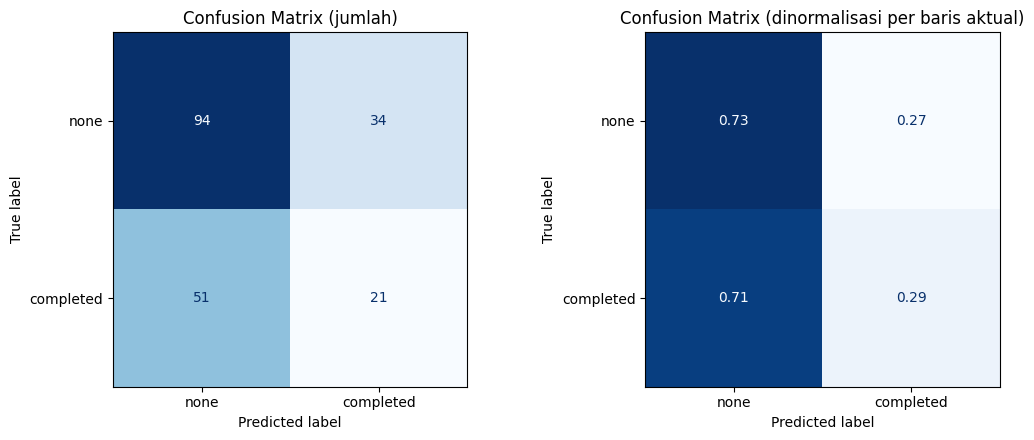

TN = 94 | FP = 34 | FN = 51 | TP = 21
Dari 72 siswa 'completed' pada data uji, hanya 21 yang terdeteksi benar (recall 29.17%).
Dari 128 siswa 'none' pada data uji, 94 terdeteksi benar (specificity 73.44%).


In [10]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay(cm, display_labels=['none', 'completed']).plot(
    ax=axes[0], cmap='Blues', colorbar=False, values_format='d')
axes[0].set_title('Confusion Matrix (jumlah)')

cm_norm = confusion_matrix(y_test, y_pred, normalize='true')
ConfusionMatrixDisplay(cm_norm, display_labels=['none', 'completed']).plot(
    ax=axes[1], cmap='Blues', colorbar=False, values_format='.2f')
axes[1].set_title('Confusion Matrix (dinormalisasi per baris aktual)')

plt.tight_layout()
plt.show()

print(f"TN = {tn} | FP = {fp} | FN = {fn} | TP = {tp}")
print(f"Dari {tp + fn} siswa 'completed' pada data uji, hanya {tp} yang terdeteksi benar (recall {tp/(tp+fn):.2%}).")
print(f"Dari {tn + fp} siswa 'none' pada data uji, {tn} terdeteksi benar (specificity {tn/(tn+fp):.2%}).")

## Sel 11 — Perbandingan dengan Baseline Kelas Mayoritas
Baseline sederhana yang selalu menebak `none` menjadi pembanding minimal. Model yang tidak lebih baik dari baseline belum menunjukkan kemampuan belajar yang berguna.

,Model,Akurasi,F1 (completed),F1 macro
0,Baseline (selalu none),0.640,0.0000,0.3902
1,k-NN (k=5),0.575,0.3307,0.5097


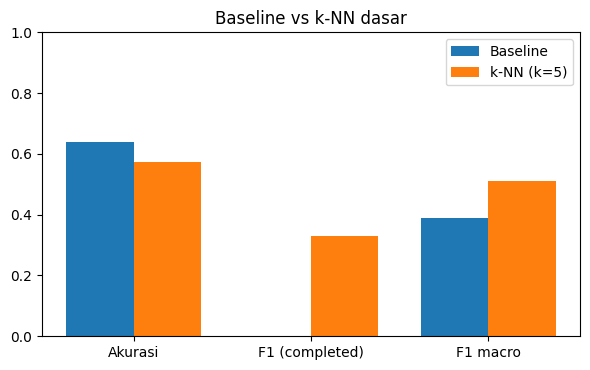

In [11]:
y_base = np.zeros_like(y_test)  # selalu menebak 'none'
acc_base = accuracy_score(y_test, y_base)
f1_base = f1_score(y_test, y_base, zero_division=0)

ringkas = pd.DataFrame({
    'Model': ['Baseline (selalu none)', f'k-NN (k={K})'],
    'Akurasi': [acc_base, acc],
    'F1 (completed)': [f1_base, f1],
    'F1 macro': [f1_score(y_test, y_base, average='macro', zero_division=0), f1_macro],
})
display(ringkas.round(4))

plt.figure(figsize=(6, 3.8))
x = np.arange(3); w = 0.38
plt.bar(x - w/2, ringkas.iloc[0, 1:].astype(float), w, label='Baseline')
plt.bar(x + w/2, ringkas.iloc[1, 1:].astype(float), w, label=f'k-NN (k={K})')
plt.xticks(x, ['Akurasi', 'F1 (completed)', 'F1 macro'])
plt.ylim(0, 1); plt.legend(); plt.title('Baseline vs k-NN dasar')
plt.tight_layout(); plt.show()

## Sel 12 — Menelusuri Penyebab: Apakah Fitur Membedakan Kelas?
Untuk menafsirkan hasil, periksa apakah fitur benar-benar berbeda antar kelas target. Jika rata-rata nilai kedua kelas hanya berselisih sedikit relatif terhadap sebarannya, k-NN akan sulit memisahkan keduanya.

,math score,reading score,writing score
test preparation course,,,
completed,69.70,73.89,74.42
none,64.08,66.53,64.50


Selisih rata-rata (completed - none) dibanding std total:
math score       0.37
reading score    0.50
writing score    0.65


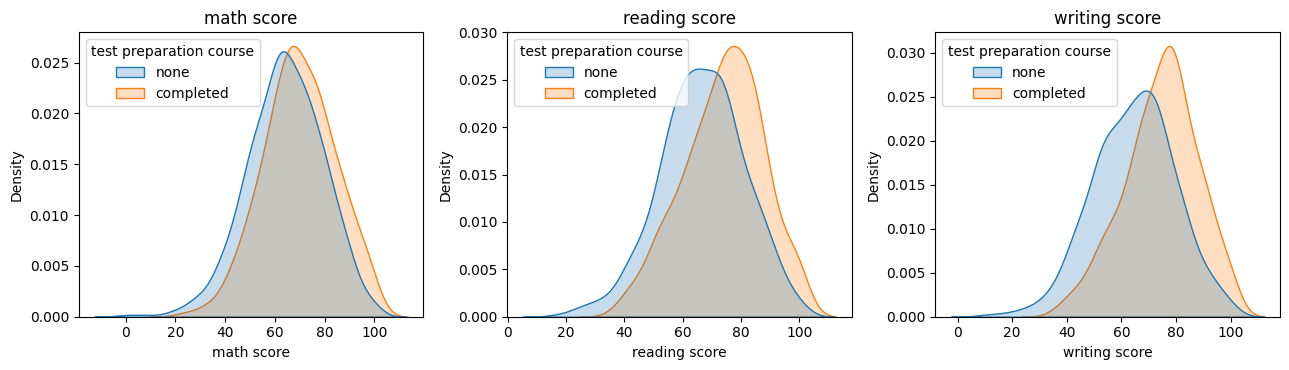

In [12]:
rata = df.groupby(target_col)[num_cols].mean().round(2)
display(rata)

selisih = (rata.loc['completed'] - rata.loc['none'])
std_total = df[num_cols].std()
print("Selisih rata-rata (completed - none) dibanding std total:")
print((selisih / std_total).round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, c in zip(axes, num_cols):
    sns.kdeplot(data=df, x=c, hue=target_col, fill=True, common_norm=False, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

## Sel 13 — Ringkasan Hasil Varian 1 (untuk Tabel Perbandingan Kelompok)
Tabel ini dapat disalin ke tabel perbandingan gabungan bersama Varian 2 dan Varian 3.

In [13]:
hasil_varian1 = pd.DataFrame([{
    'Varian': '1 - Dasar',
    'Model': f'k-NN (k={K})',
    'Fitur': f'{X_enc.shape[1]} kolom (7 fitur asli, setelah one-hot)',
    'Akurasi': round(acc, 4),
    'F1 (completed)': round(f1, 4),
    'F1 macro': round(f1_macro, 4),
    'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
}])
display(hasil_varian1)

hasil_varian1.to_csv('hasil_varian_1.csv', index=False)
print("Disimpan ke hasil_varian_1.csv")

,Varian,Model,Fitur,Akurasi,F1 (completed),F1 macro,TN,FP,FN,TP
0,1 - Dasar,k-NN (k=5),"14 kolom (7 fitur asli, setelah one-hot)",0.575,0.3307,0.5097,94,34,51,21


Disimpan ke hasil_varian_1.csv


## Sel 14 — Menyimpan Artefak untuk Pertemuan 13
Seluruh hasil pertemuan ini disimpan dalam satu berkas di folder proyek pada Drive. Pertemuan 13 memuat berkas itu dan melanjutkan **tanpa melatih ulang apa pun**.

Notebook Varian 1 tidak memakai pencarian parameter (`GridSearchCV`) dan tidak melatih Naive Bayes, jadi `knn` berisi model k-NN (k=5) dan `nb` diisi `None`. Skor validasi silang (`cv_knn`) dihitung dengan `Pipeline` supaya scaler di-fit ulang di tiap lipatan dan tidak ada kebocoran data.

In [14]:
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 1) Hubungkan Drive dan tentukan folder proyek
try:
    from google.colab import drive
    drive.mount('/content/drive')
    FOLDER = '/content/drive/MyDrive/ProyekAkhir_ML'
except ImportError:
    FOLDER = 'artefak'          # di luar Colab: simpan di folder lokal
os.makedirs(FOLDER, exist_ok=True)

# 2) Skor validasi silang k-NN (k=5) pada DATA LATIH saja, scaler di dalam pipeline
pipa_knn = Pipeline([
    ('prep', ColumnTransformer([('num', StandardScaler(), num_cols)],
                               remainder='passthrough')),
    ('knn', KNeighborsClassifier(n_neighbors=K)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
skor_cv = cross_val_score(pipa_knn, X_train, y_train, cv=cv, scoring='accuracy')
print(f"CV akurasi k-NN (k={K}), 5 lipatan: {skor_cv.mean():.4f} (+/- {skor_cv.std():.4f})")

# 3) Kumpulkan artefak
artefak = {
    # Data siap pakai (X_* sudah di-encode dan distandardisasi dengan scaler data latih)
    'X_train': X_train_s, 'X_test': X_test_s,
    'y_train': y_train, 'y_test': y_test,
    'numerik': num_cols, 'kategorik': cat_cols,
    # Model dan pra-pemroses
    'knn': knn, 'nb': None,                      # Varian 1 tidak melatih Naive Bayes
    'scaler': scaler, 'fitur': list(X_enc.columns),
    # Parameter dan skor validasi silang
    'param_knn': knn.get_params(), 'param_nb': None,
    'cv_knn': float(skor_cv.mean()), 'cv_nb': None,
    # Hasil pada data uji sebagai tolok ukur
    'hasil_uji': {'akurasi': float(acc), 'f1_completed': float(f1),
                  'f1_macro': float(f1_macro), 'baseline': float(baseline),
                  'confusion_matrix': cm.tolist()},
    # Metadata
    'kolom_encoding': int(X_enc.shape[1]),
    'seed': RANDOM_STATE, 'test_size': TEST_SIZE, 'k': K,
    'versi_sklearn': sklearn.__version__,
}

jalur = os.path.join(FOLDER, 'artefak_p12.joblib')
joblib.dump(artefak, jalur)
print('Tersimpan:', jalur)
print('Ukuran   :', round(os.path.getsize(jalur) / 1024, 1), 'KB')

Mounted at /content/drive
CV akurasi k-NN (k=5), 5 lipatan: 0.6088 (+/- 0.0297)
Tersimpan: /content/drive/MyDrive/ProyekAkhir_ML/artefak_p12.joblib
Ukuran   : 350.4 KB


### Uji Muat Ulang Artefak
Memastikan berkas bisa dimuat dan model langsung memberi prediksi yang sama, tanpa `fit` ulang. Inilah yang akan dilakukan Pertemuan 13.

In [15]:
muat = joblib.load(jalur)
print("Kunci artefak:", list(muat.keys()))
print("Versi sklearn saat disimpan:", muat['versi_sklearn'], "| sekarang:", sklearn.__version__)

pred_muat = muat['knn'].predict(muat['X_test'])
print("Prediksi identik dengan model asli:", bool((pred_muat == y_pred).all()))
print(f"Akurasi data uji dari artefak: {accuracy_score(muat['y_test'], pred_muat):.4f}")

Kunci artefak: ['X_train', 'X_test', 'y_train', 'y_test', 'numerik', 'kategorik', 'knn', 'nb', 'scaler', 'fitur', 'param_knn', 'param_nb', 'cv_knn', 'cv_nb', 'hasil_uji', 'kolom_encoding', 'seed', 'test_size', 'k', 'versi_sklearn']
Versi sklearn saat disimpan: 1.6.1 | sekarang: 1.6.1
Prediksi identik dengan model asli: True
Akurasi data uji dari artefak: 0.5750


## Sel 15 — Interpretasi Hasil (diisi dari keluaran sel di atas)

### 1. Apakah k-NN dasar lebih baik daripada baseline?
Akurasi k-NN (k=5) sekitar **57,5%**, **lebih rendah** daripada baseline kelas mayoritas (64%, selalu menebak `none`; selisih sekitar −6,7 poin). Artinya model belum lebih berguna daripada tebakan tanpa fitur. Akurasi yang tampak "lumayan" justru berasal dari banyaknya kelas `none`, bukan dari kemampuan model memahami pola.

### 2. Apa yang ditunjukkan confusion matrix?
Confusion matrix sekitar `[[94, 34], [51, 21]]` (TN=94, FP=34, FN=51, TP=21).
- Dari 72 siswa `completed`, hanya **21** yang terdeteksi (recall ≈ 29%); **51** salah diprediksi `none` (FN besar).
- Dari 128 siswa `none`, **94** terdeteksi benar (≈ 73%).
- Model cenderung memihak kelas mayoritas `none`; kesalahan terbesarnya adalah melewatkan siswa yang sebenarnya mengikuti kursus.

### 3. Mengapa F1-score (completed) rendah?
F1 kelas `completed` sekitar **0,33**, dan F1 macro sekitar **0,51**. F1 adalah rata-rata harmonik precision dan recall; karena recall `completed` rendah (≈ 0,29, banyak FN) dan precision juga rendah (≈ 0,38, banyak FP), F1 ikut rendah. F1 inilah yang mengungkap kelemahan model, yang tersembunyi oleh akurasi.

### 4. Mengapa akurasi saja menyesatkan pada data ini?
Data tidak seimbang (64,2% `none`). Model yang hampir selalu menebak `none` sudah mendapat akurasi sekitar 64%. Karena itu akurasi harus dibaca bersama baseline, F1, dan confusion matrix, bukan sendirian.

### 5. Apa kemungkinan penyebab kinerja rendah?
- **Fitur lemah.** Pada Sel 12, selisih rata-rata nilai antara kelas `completed` dan `none` hanya sekitar 0,4–0,65 simpangan baku (matematika ≈ 0,37, membaca ≈ 0,50, menulis ≈ 0,65) dan distribusi kedua kelas saling tumpang tindih besar, sehingga kedua kelas sulit dipisahkan di ruang fitur.
- **Ketidakseimbangan kelas.** Dengan k=5, tetangga terdekat didominasi kelas `none` (mayoritas), sehingga prediksi condong ke `none`.
- **Dimensi campuran.** Fitur one-hot (0/1) ikut menentukan jarak bersama tiga nilai numerik, dan fitur kategorikal seperti gender atau etnis hampir tidak informatif terhadap status kursus, sehingga justru menambah derau pada perhitungan jarak.
- **k=5 belum tentu optimal.** Nilai k lain mungkin menghasilkan hasil berbeda; ini dikaji pada Varian 2.

### 6. Peran Varian 1 dalam proyek
Varian ini menjadi **tolok ukur**: konfigurasi apa adanya, tanpa penyetelan. Varian 2 menguji apakah mengubah k memperbaiki hasil, dan Varian 3 menguji apakah algoritma berbeda (Naive Bayes) lebih sesuai untuk data ini. Hasil yang kurang bagus pada varian dasar bukan kegagalan; justru memberi dasar yang jelas untuk menilai apakah varian lain memberi perbaikan nyata.

### 7. Kesimpulan singkat
k-NN (k=5) dengan fitur terstandardisasi belum mampu mengalahkan baseline dan lemah dalam mengenali siswa yang menyelesaikan kursus (F1 completed ≈ 0,33). Hal ini konsisten dengan temuan eksplorasi bahwa perbedaan nilai antar kelas hanya moderat (siswa `completed` memang rata-rata lebih tinggi, tetapi sebarannya tumpang tindih). Kesimpulan akhir tentang algoritma terbaik ditentukan setelah membandingkan dengan Varian 2 dan 3.
